In [2]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error
from skimage.metrics import structural_similarity

In [6]:
gray_image = cv2.imread('image/sar_1_gray.jpg',0)

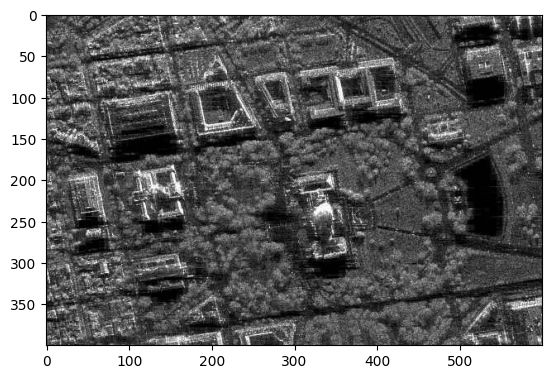

In [27]:
plt.imshow(gray_image,cmap='gray') # без  cmap='gray' цвета могут быть некоректными

In [28]:
histSize = 256# количество бинов в гистограмме (0-255)
histRange = (0, 256)# диапазон значений яркости
accumulate = False# не накапливать гистограмму между вызовами

b_hist = cv2.calcHist([gray_image], [0], None, [histSize], histRange, accumulate=accumulate)# ну вместо b gray_image подставил и всё)

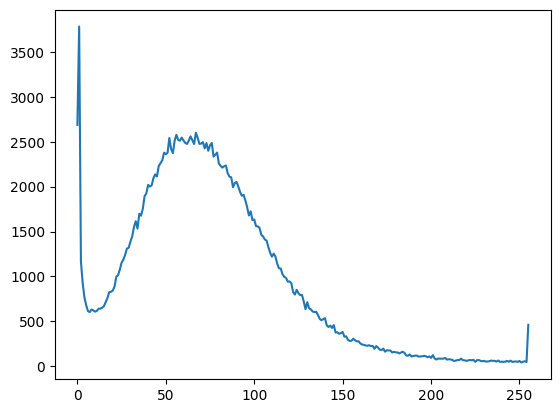

In [29]:
plt.plot(b_hist)

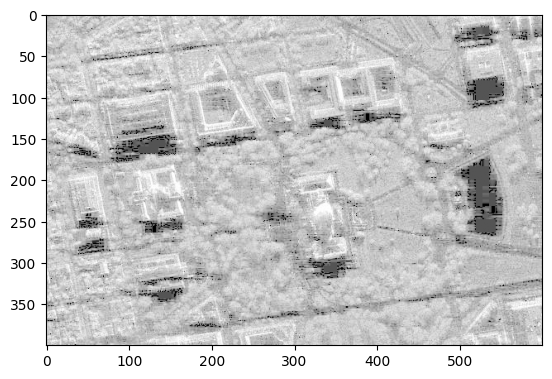

In [30]:
gamma = 0.2
output_image = 255 * (gray_image / 255) ** gamma
plt.imshow(output_image,cmap='gray')

In [31]:
mse = mean_squared_error(gray_image, output_image)
ssim = structural_similarity(gray_image, output_image, data_range=255)

print(f"MSE: {mse}")
print(f"SSIM: {ssim}")

MSE: 14128.053543036754
SSIM: 0.5019327679711567


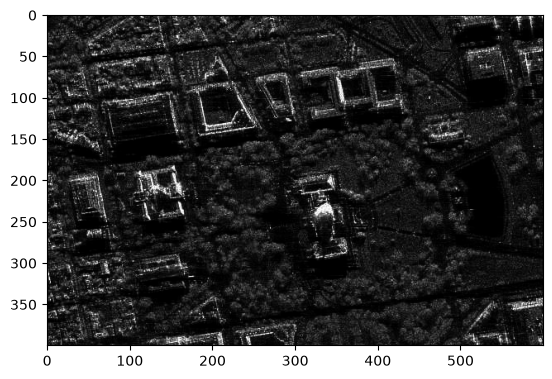

In [7]:
gamma_gt_1 = 2
output_image_gamma_gt_1 = 255 * (gray_image / 255) ** gamma_gt_1
plt.imshow(output_image_gamma_gt_1, cmap='gray')


In [8]:
mse_gamma_gt_1 = mean_squared_error(gray_image, output_image_gamma_gt_1)
ssim_gamma_gt_1 = structural_similarity(gray_image, output_image_gamma_gt_1, data_range=255)

print(f"MSE: {mse_gamma_gt_1}")
print(f"SSIM: {ssim_gamma_gt_1}")


MSE: 2342.502472022042
SSIM: 0.5356896237616672


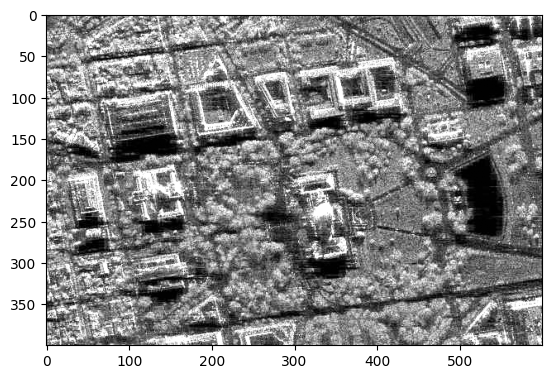

In [32]:
mean = gray_image.mean()
std = gray_image.std()

eq_gray_image = cv2.equalizeHist(gray_image)

mean_eq_gray_image = eq_gray_image.mean()
std_eq_gray_image = eq_gray_image.std()

corrected_image = mean_eq_gray_image + (gray_image.astype(np.int16) - mean) * (std_eq_gray_image / std)
corrected_image = np.clip(corrected_image, 0, 255).astype(np.uint8)

plt.imshow(corrected_image, cmap='gray')

In [33]:
_, thresh1 = cv2.threshold(gray_image, 124, 255, cv2.THRESH_BINARY)# _ отбрасывает первый возращаемый параметр
_, thresh2 = cv2.threshold(gray_image, 50, 255, cv2.THRESH_BINARY) 
_, thresh3 = cv2.threshold(gray_image, 150, 255, cv2.THRESH_BINARY)
# if пиксель >= порог:  пиксель = 255 (белый) else: пиксель = 0 (черный)

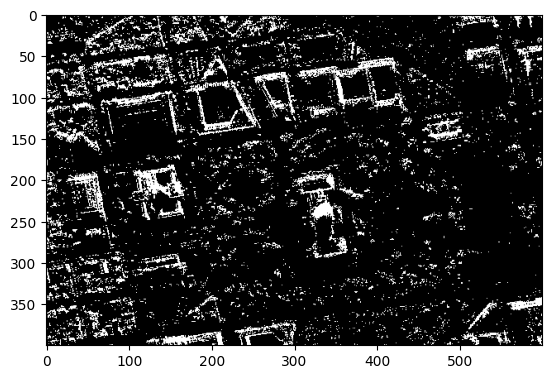

In [34]:
plt.imshow(thresh1,cmap='gray')

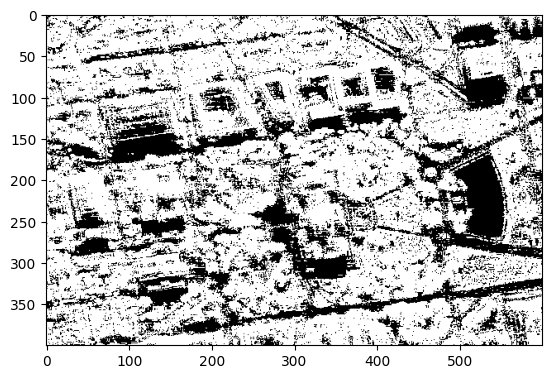

In [35]:
plt.imshow(thresh2, cmap='gray')

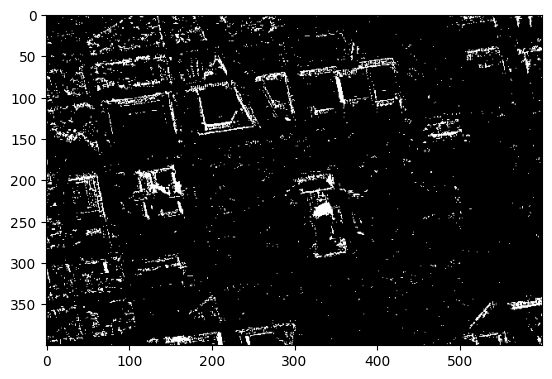

In [36]:
plt.imshow(thresh3,cmap='gray')